In [1]:
from pathlib import Path
from datetime import datetime
from uuid import uuid4
import os
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display

CUSTOM_CLEAN_DIR = None
search_roots = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
paths = ([Path(CUSTOM_CLEAN_DIR)] if CUSTOM_CLEAN_DIR else
         [r / sub for r in search_roots for sub in ("clean_data", "BI10_ROUND02_DATASET/clean_data")])
required_files = ("CONTRACT_clean.csv", "CUSTOMER_clean.csv")
CLEAN_DIR = next((p.resolve() for p in paths if all((p / f).is_file() for f in required_files)), None)
if CLEAN_DIR is None:
    raise FileNotFoundError("Cannot locate clean_data with CONTRACT_clean.csv and CUSTOMER_clean.csv. Set CUSTOM_CLEAN_DIR.")
RUN_DIR = CLEAN_DIR.parent / "C1_STAT_OUTPUT" / ("run_" + datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:6])
TABLE_DIR = RUN_DIR / "tables"
FIG_DIR = RUN_DIR / "figures"
SCRATCH_DIR = RUN_DIR / "scratch"
for directory in (TABLE_DIR, FIG_DIR, SCRATCH_DIR):
    directory.mkdir(parents=True, exist_ok=True)
C1_DB = duckdb.connect(database=":memory:")
C1_DB.execute("SET threads = 4")
C1_DB.execute("SET memory_limit = '4GB'")
C1_DB.execute("SET temp_directory = "+"'"+str(SCRATCH_DIR.as_posix()).replace("'","''")+"'")
RESULTS = {}

def save(name, frame, shown=15):
    RESULTS[name] = frame
    frame.to_csv(TABLE_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    print(f"{name} | {len(frame):,} rows")
    if shown:
        display(frame.head(shown))
    return frame

print("CLEAN:", CLEAN_DIR)
print("OUTPUT:", RUN_DIR)
print("DuckDB:", duckdb.__version__)

CLEAN: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\clean_data
OUTPUT: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STAT_OUTPUT\run_20261018_085019_1c3fc7
DuckDB: 1.5.6


In [2]:
def sql_literal(value):
    return "'" + str(value).replace("'", "''") + "'"

for t in ("CONTRACT", "CUSTOMER"):
    p = CLEAN_DIR / f"{t}_clean.csv"
    read_sql = f"read_csv({sql_literal(p.as_posix())}, header=true, all_varchar=true, delim=',', quote='\"', escape='\"', ignore_errors=false)"
    C1_DB.execute(f"CREATE TEMP VIEW c1_src_{t.lower()} AS SELECT * FROM {read_sql}")

required_contract = {
    "SKP_CREDIT_CASE", "SKP_CLIENT", "NAME_CREDIT_STATUS", "PRODUCT",
    "AMT_INCOME_MAIN", "ANNUITY", "AMT_CREDIT", "INIT_PAY",
    "FIRST_DUE", "SECOND_DUE", "THIRD_DUE", "FOURTH_DUE", "APPLY_CONTRACT_TIME"
}
contract_cols = set(C1_DB.execute("SELECT * FROM c1_src_contract LIMIT 0").df().columns.str.upper())
customer_cols = set(C1_DB.execute("SELECT * FROM c1_src_customer LIMIT 0").df().columns.str.upper())
missing = sorted(required_contract - contract_cols)
if missing or "SKP_CLIENT" not in customer_cols:
    raise ValueError(f"Clean CSV schema mismatch: contract missing={missing}; customer SKP_CLIENT present={'SKP_CLIENT' in customer_cols}")
source_health = C1_DB.execute("""
SELECT 'CONTRACT' AS table_name, COUNT(*) AS n_rows,
       COUNT(DISTINCT NULLIF(TRIM(SKP_CREDIT_CASE), '')) AS distinct_cases,
       COUNT(DISTINCT NULLIF(TRIM(SKP_CLIENT), '')) AS distinct_clients,
       COUNT(*) FILTER (WHERE SKP_CREDIT_CASE IS NULL OR TRIM(SKP_CREDIT_CASE)='') AS missing_case_id
FROM c1_src_contract
UNION ALL
SELECT 'CUSTOMER', COUNT(*), NULL,
       COUNT(DISTINCT NULLIF(TRIM(SKP_CLIENT), '')), NULL
FROM c1_src_customer
""").df()
save("01_source_inventory", source_health)

01_source_inventory | 2 rows


,table_name,n_rows,distinct_cases,distinct_clients,missing_case_id
0,CONTRACT,4280377,4280377,1000528,0
1,CUSTOMER,1000528,<NA>,1000528,<NA>


,table_name,n_rows,distinct_cases,distinct_clients,missing_case_id
0,CONTRACT,4280377,4280377,1000528,0
1,CUSTOMER,1000528,<NA>,1000528,<NA>


In [3]:
C1_DB.execute("""
CREATE TEMP TABLE c1_case AS
WITH raw AS (
    SELECT
        NULLIF(TRIM(SKP_CREDIT_CASE), '') AS case_id,
        NULLIF(TRIM(SKP_CLIENT), '') AS client_id,
        NULLIF(UPPER(TRIM(PRODUCT)), '') AS product_raw,
        NULLIF(UPPER(TRIM(NAME_CREDIT_STATUS)), '') AS status_raw,
        TRY_CAST(AMT_INCOME_MAIN AS DOUBLE) AS income_val,
        TRY_CAST(ANNUITY AS DOUBLE) AS annuity_val,
        TRY_CAST(AMT_CREDIT AS DOUBLE) AS credit_val,
        TRY_CAST(INIT_PAY AS DOUBLE) AS downpay_val,
        TRY_CAST(FIRST_DUE AS INTEGER) AS d1_raw,
        TRY_CAST(SECOND_DUE AS INTEGER) AS d2_raw,
        TRY_CAST(THIRD_DUE AS INTEGER) AS d3_raw,
        TRY_CAST(FOURTH_DUE AS INTEGER) AS d4_raw,
        TRY_CAST(APPLY_CONTRACT_TIME AS TIMESTAMP) AS apply_ts_raw
    FROM c1_src_contract
), grouped AS (
    SELECT
        case_id, MIN(client_id) AS client_id,
        COUNT(*) AS source_records,
        (COUNT(client_id) = COUNT(*) AND MIN(client_id) = MAX(client_id)) AS client_consistent,
        CASE WHEN COUNT(product_raw)=COUNT(*) AND MIN(product_raw)=MAX(product_raw)
             THEN MIN(product_raw) END AS product,
        CASE WHEN COUNT(status_raw)=COUNT(*) AND MIN(status_raw)=MAX(status_raw)
             THEN MIN(status_raw) END AS credit_status,
        CASE WHEN COUNT(income_val)=COUNT(*) AND MIN(income_val)=MAX(income_val)
                       AND MIN(income_val)>0 THEN MIN(income_val) END AS income,
        CASE WHEN COUNT(annuity_val)=COUNT(*) AND MIN(annuity_val)=MAX(annuity_val)
                       AND MIN(annuity_val)>0 THEN MIN(annuity_val) END AS annuity,
        CASE WHEN COUNT(credit_val)=COUNT(*) AND MIN(credit_val)=MAX(credit_val)
                       AND MIN(credit_val)>0 THEN MIN(credit_val) END AS credit_amount,
        CASE WHEN COUNT(downpay_val)=COUNT(*) AND MIN(downpay_val)=MAX(downpay_val)
                       AND MIN(downpay_val)>=0 THEN MIN(downpay_val) END AS down_payment,
        CASE WHEN COUNT(d1_raw)=COUNT(*) AND MIN(d1_raw)=MAX(d1_raw)
                       AND MIN(d1_raw) IN (0,1) THEN MIN(d1_raw) END AS due1,
        CASE WHEN COUNT(d2_raw)=COUNT(*) AND MIN(d2_raw)=MAX(d2_raw)
                       AND MIN(d2_raw) IN (0,1) THEN MIN(d2_raw) END AS due2,
        CASE WHEN COUNT(d3_raw)=COUNT(*) AND MIN(d3_raw)=MAX(d3_raw)
                       AND MIN(d3_raw) IN (0,1) THEN MIN(d3_raw) END AS due3,
        CASE WHEN COUNT(d4_raw)=COUNT(*) AND MIN(d4_raw)=MAX(d4_raw)
                       AND MIN(d4_raw) IN (0,1) THEN MIN(d4_raw) END AS due4,
        CASE WHEN COUNT(apply_ts_raw)=COUNT(*) AND MIN(apply_ts_raw)=MAX(apply_ts_raw)
                       THEN MIN(apply_ts_raw) END AS application_time
    FROM raw WHERE case_id IS NOT NULL GROUP BY case_id
), flags AS (
    SELECT *,
        (credit_status IN ('ACTIVE','FINISHED','PAID OFF','SIGNED','WRITTEN OFF')) AS is_signed,
        (credit_status IN ('FINISHED','PAID OFF','WRITTEN OFF')) AS is_resolved_proxy,
        CASE WHEN credit_status IS NOT NULL THEN CAST(credit_status='WRITTEN OFF' AS INTEGER) END AS written_off,
        CASE WHEN due1 IS NOT NULL AND due2 IS NOT NULL AND due3 IS NOT NULL AND due4 IS NOT NULL
             THEN GREATEST(due1,due2,due3,due4) END AS any_due,
        CASE WHEN credit_status IN ('ACTIVE','FINISHED','PAID OFF','SIGNED','WRITTEN OFF')
                       AND income>0 AND annuity>0 THEN annuity/income END AS installment_income_ratio,
        CASE WHEN product IN ('CD','TW') AND credit_amount>0 AND down_payment IS NOT NULL
             THEN down_payment/(down_payment+credit_amount) END AS down_payment_ratio,
        EXTRACT(YEAR FROM application_time)::INTEGER AS apply_year
    FROM grouped
)
SELECT * FROM flags
""")
print("Case-level table created:", C1_DB.execute("SELECT COUNT(*) FROM c1_case").fetchone()[0])

Case-level table created: 4280377


In [4]:
quality = C1_DB.execute("""
SELECT COUNT(*) AS unique_cases,
       SUM(source_records) AS source_records_with_case_id,
       COUNT(*) FILTER (WHERE source_records>1) AS repeated_cases,
       COUNT(*) FILTER (WHERE NOT client_consistent) AS ambiguous_client_cases,
       COUNT(*) FILTER (WHERE product IS NULL) AS ambiguous_product_cases,
       COUNT(*) FILTER (WHERE credit_status IS NULL) AS ambiguous_status_cases,
       COUNT(*) FILTER (WHERE income IS NULL) AS income_not_usable_cases,
       COUNT(*) FILTER (WHERE annuity IS NULL) AS annuity_not_usable_cases,
       COUNT(*) FILTER (WHERE any_due IS NULL) AS due_flags_not_usable_cases,
       COUNT(*) FILTER (WHERE installment_income_ratio IS NOT NULL) AS ratio_eligible_cases,
       COUNT(*) FILTER (WHERE is_signed) AS signed_status_cases,
       COUNT(*) FILTER (WHERE is_resolved_proxy) AS resolved_status_cases
FROM c1_case
""").df()
save("02_case_grain_quality", quality)

coverage = C1_DB.execute("""
SELECT COALESCE(product,'[UNKNOWN/MIXED]') AS product,
       COUNT(*) AS n_cases,
       COUNT(*) FILTER (WHERE is_signed) AS n_signed,
       COUNT(*) FILTER (WHERE is_signed AND installment_income_ratio IS NOT NULL) AS n_ratio_eligible,
       COUNT(*) FILTER (WHERE is_signed AND any_due IS NOT NULL) AS n_due_observed,
       COUNT(*) FILTER (WHERE is_resolved_proxy) AS n_resolved_proxy,
       COUNT(*) FILTER (WHERE is_signed AND written_off=1) AS n_written_off,
       ROUND(100.0*COUNT(*) FILTER (WHERE is_signed AND installment_income_ratio IS NOT NULL)
             / NULLIF(COUNT(*) FILTER (WHERE is_signed),0),2) AS ratio_coverage_pct,
       ROUND(100.0*COUNT(*) FILTER (WHERE is_signed AND any_due IS NOT NULL)
             / NULLIF(COUNT(*) FILTER (WHERE is_signed),0),2) AS due_field_coverage_pct
FROM c1_case GROUP BY 1 ORDER BY n_cases DESC
""").df()
save("03_product_eligibility", coverage, 20)

02_case_grain_quality | 1 rows


,unique_cases,source_records_with_case_id,repeated_cases,ambiguous_client_cases,ambiguous_product_cases,ambiguous_status_cases,income_not_usable_cases,annuity_not_usable_cases,due_flags_not_usable_cases,ratio_eligible_cases,signed_status_cases,resolved_status_cases
0,4280377,4280377.0,0,0,28348,0,11101,381862,0,2604394,2887190,2037903


03_product_eligibility | 8 rows


,product,n_cases,n_signed,n_ratio_eligible,n_due_observed,n_resolved_proxy,n_written_off,ratio_coverage_pct,due_field_coverage_pct
0,CD,3095684,2109898,2106354,2109898,1694240,8073,99.83,100.0
1,CL,565521,377312,374871,377312,216921,3780,99.35,100.0
2,BNPL,211481,178192,0,178192,5712,147,0.00,100.0
3,CC,135823,98597,0,98597,41025,339,0.00,100.0
4,TW,133928,100793,100771,100793,62302,1514,99.98,100.0
5,CW,109591,22397,22397,22397,17702,667,100.00,100.0
6,[UNKNOWN/MIXED],28348,0,0,0,0,0,NaN,NaN
7,IN,1,1,1,1,1,0,100.00,100.0


,product,n_cases,n_signed,n_ratio_eligible,n_due_observed,n_resolved_proxy,n_written_off,ratio_coverage_pct,due_field_coverage_pct
0,CD,3095684,2109898,2106354,2109898,1694240,8073,99.83,100.0
1,CL,565521,377312,374871,377312,216921,3780,99.35,100.0
2,BNPL,211481,178192,0,178192,5712,147,0.00,100.0
3,CC,135823,98597,0,98597,41025,339,0.00,100.0
4,TW,133928,100793,100771,100793,62302,1514,99.98,100.0
5,CW,109591,22397,22397,22397,17702,667,100.00,100.0
6,[UNKNOWN/MIXED],28348,0,0,0,0,0,NaN,NaN
7,IN,1,1,1,1,1,0,100.00,100.0


In [5]:
ratio_stats = C1_DB.execute("""
SELECT COALESCE(product,'[UNKNOWN/MIXED]') AS product,
       COUNT(*) AS n_cases,
       ROUND(100*AVG(installment_income_ratio),3) AS mean_pct,
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.10),3) AS p10_pct,
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.25),3) AS p25_pct,
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.50),3) AS p50_pct,
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.75),3) AS p75_pct,
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.90),3) AS p90_pct,
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.95),3) AS p95_pct,
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.99),3) AS p99_pct,
       COUNT(*) FILTER (WHERE installment_income_ratio>=1) AS n_ge_100pct
FROM c1_case
WHERE installment_income_ratio IS NOT NULL
GROUP BY 1
UNION ALL
SELECT 'ALL', COUNT(*), ROUND(100*AVG(installment_income_ratio),3),
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.10),3),
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.25),3),
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.50),3),
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.75),3),
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.90),3),
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.95),3),
       ROUND(100*QUANTILE_CONT(installment_income_ratio,0.99),3),
       COUNT(*) FILTER (WHERE installment_income_ratio>=1)
FROM c1_case WHERE installment_income_ratio IS NOT NULL
ORDER BY n_cases DESC
""").df()
save("04_ratio_exact_percentiles", ratio_stats, 20)

04_ratio_exact_percentiles | 6 rows


,product,n_cases,mean_pct,p10_pct,p25_pct,p50_pct,p75_pct,p90_pct,p95_pct,p99_pct,n_ge_100pct
0,ALL,2604394,19.149,5.773,8.060,11.609,16.825,23.633,29.000,42.800,144
1,CD,2106354,18.949,5.480,7.587,10.650,15.011,20.220,24.186,33.857,57
2,CL,374871,18.215,8.053,11.423,16.387,22.877,30.669,36.238,49.019,31
3,TW,100771,27.136,12.683,17.674,25.048,34.175,44.314,51.550,66.556,56
4,CW,22397,17.637,9.050,12.077,16.527,21.900,27.583,31.776,40.050,0
5,IN,1,16.414,16.414,16.414,16.414,16.414,16.414,16.414,16.414,0


,product,n_cases,mean_pct,p10_pct,p25_pct,p50_pct,p75_pct,p90_pct,p95_pct,p99_pct,n_ge_100pct
0,ALL,2604394,19.149,5.773,8.060,11.609,16.825,23.633,29.000,42.800,144
1,CD,2106354,18.949,5.480,7.587,10.650,15.011,20.220,24.186,33.857,57
2,CL,374871,18.215,8.053,11.423,16.387,22.877,30.669,36.238,49.019,31
3,TW,100771,27.136,12.683,17.674,25.048,34.175,44.314,51.550,66.556,56
4,CW,22397,17.637,9.050,12.077,16.527,21.900,27.583,31.776,40.050,0
5,IN,1,16.414,16.414,16.414,16.414,16.414,16.414,16.414,16.414,0


In [6]:
numeric_distributions = C1_DB.execute("""
SELECT COALESCE(product,'[UNKNOWN/MIXED]') AS product,
       COUNT(*) AS n_signed,
       COUNT(income) AS n_reliable_income,
       COUNT(annuity) AS n_reliable_annuity,
       COUNT(credit_amount) AS n_reliable_credit,
       ROUND(QUANTILE_CONT(income,0.50),0) AS income_p50,
       ROUND(QUANTILE_CONT(income,0.90),0) AS income_p90,
       ROUND(QUANTILE_CONT(annuity,0.50),0) AS annuity_p50,
       ROUND(QUANTILE_CONT(annuity,0.90),0) AS annuity_p90,
       ROUND(QUANTILE_CONT(credit_amount,0.50),0) AS credit_p50,
       ROUND(QUANTILE_CONT(credit_amount,0.90),0) AS credit_p90,
       ROUND(CORR(LN(income),LN(annuity)),4) AS log_income_vs_log_annuity_corr,
       ROUND(CORR(installment_income_ratio,LN(income)),4) AS ratio_vs_log_income_corr,
       ROUND(CORR(installment_income_ratio,LN(annuity)),4) AS ratio_vs_log_annuity_corr
FROM c1_case WHERE is_signed GROUP BY 1
ORDER BY n_signed DESC
""").df()
save('04b_income_annuity_credit_by_product',numeric_distributions,20)

04b_income_annuity_credit_by_product | 7 rows


,product,n_signed,n_reliable_income,n_reliable_annuity,n_reliable_credit,income_p50,income_p90,annuity_p50,annuity_p90,credit_p50,credit_p90,log_income_vs_log_annuity_corr,ratio_vs_log_income_corr,ratio_vs_log_annuity_corr
0,CD,2109898,2107771,2108481,2109594,10000000.0,15000000.0,1011000.0,1843000.0,5290000.0,11543000.0,0.3144,-0.0313,0.0007
1,CL,377312,376165,376018,377312,14000000.0,25000000.0,2149000.0,4235000.0,21000000.0,60000000.0,0.4626,-0.4723,0.4904
2,BNPL,178192,178192,0,0,10000000.0,18000000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TW,100793,100771,100793,100793,10000000.0,17000000.0,2404000.0,3896000.0,21000000.0,39700000.0,0.4035,-0.6240,0.3912
4,CC,98597,98597,0,97720,12000000.0,23000000.0,NaN,NaN,20000000.0,45000000.0,NaN,NaN,NaN
5,CW,22397,22397,22397,22397,11000000.0,20000000.0,1921000.0,2847000.0,20000000.0,40000000.0,0.3213,-0.6854,0.4038
6,IN,1,1,1,1,7000000.0,7000000.0,1149000.0,1149000.0,12000.0,12000.0,NaN,NaN,NaN


,product,n_signed,n_reliable_income,n_reliable_annuity,n_reliable_credit,income_p50,income_p90,annuity_p50,annuity_p90,credit_p50,credit_p90,log_income_vs_log_annuity_corr,ratio_vs_log_income_corr,ratio_vs_log_annuity_corr
0,CD,2109898,2107771,2108481,2109594,10000000.0,15000000.0,1011000.0,1843000.0,5290000.0,11543000.0,0.3144,-0.0313,0.0007
1,CL,377312,376165,376018,377312,14000000.0,25000000.0,2149000.0,4235000.0,21000000.0,60000000.0,0.4626,-0.4723,0.4904
2,BNPL,178192,178192,0,0,10000000.0,18000000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TW,100793,100771,100793,100793,10000000.0,17000000.0,2404000.0,3896000.0,21000000.0,39700000.0,0.4035,-0.6240,0.3912
4,CC,98597,98597,0,97720,12000000.0,23000000.0,NaN,NaN,20000000.0,45000000.0,NaN,NaN,NaN
5,CW,22397,22397,22397,22397,11000000.0,20000000.0,1921000.0,2847000.0,20000000.0,40000000.0,0.3213,-0.6854,0.4038
6,IN,1,1,1,1,7000000.0,7000000.0,1149000.0,1149000.0,12000.0,12000.0,NaN,NaN,NaN


In [7]:
C1_DB.execute("""
CREATE TEMP VIEW c1_ratio_bins AS
SELECT *,
       CASE WHEN installment_income_ratio<0.10 THEN 1
            WHEN installment_income_ratio<0.20 THEN 2
            WHEN installment_income_ratio<0.30 THEN 3
            WHEN installment_income_ratio<0.40 THEN 4
            WHEN installment_income_ratio<0.50 THEN 5
            WHEN installment_income_ratio<1.00 THEN 6 ELSE 7 END AS band_order,
       CASE WHEN installment_income_ratio<0.10 THEN '[0%,10%)'
            WHEN installment_income_ratio<0.20 THEN '[10%,20%)'
            WHEN installment_income_ratio<0.30 THEN '[20%,30%)'
            WHEN installment_income_ratio<0.40 THEN '[30%,40%)'
            WHEN installment_income_ratio<0.50 THEN '[40%,50%)'
            WHEN installment_income_ratio<1.00 THEN '[50%,100%)'
            ELSE '>=100%' END AS ratio_band
FROM c1_case WHERE installment_income_ratio IS NOT NULL
""")

band_sql = """
SELECT {prod_expr} AS product, band_order, ratio_band,
       COUNT(*) AS n_cases,
       COUNT(*) FILTER (WHERE any_due IS NOT NULL) AS n_due_available,
       COUNT(*) FILTER (WHERE any_due=1) AS n_any_due,
       COUNT(*) FILTER (WHERE due4 IS NOT NULL) AS n_due4_available,
       COUNT(*) FILTER (WHERE due4=1) AS n_due4,
       COUNT(*) FILTER (WHERE written_off=1) AS n_written_off,
       COUNT(*) FILTER (WHERE is_resolved_proxy) AS n_resolved_proxy,
       COUNT(*) FILTER (WHERE is_resolved_proxy AND written_off=1) AS n_written_off_resolved
FROM c1_ratio_bins
GROUP BY {group_expr}
"""
part1 = band_sql.format(prod_expr="COALESCE(product,'[UNKNOWN/MIXED]')", group_expr="1,2,3")
part2 = band_sql.format(prod_expr="'ALL'", group_expr="2,3")
ratio_bands = C1_DB.execute(f"{part1} UNION ALL {part2} ORDER BY product, band_order").df()

def wilson(k, n, z=1.959963984540054):
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    p = np.divide(k, n, out=np.full_like(k, np.nan), where=n>0)
    den = 1 + z*z/np.where(n>0,n,np.nan)
    center = (p + z*z/(2*np.where(n>0,n,np.nan)))/den
    half = z*np.sqrt((p*(1-p)+z*z/(4*np.where(n>0,n,np.nan)))/np.where(n>0,n,np.nan))/den
    return 100*(center-half), 100*(center+half)

for prefix, events, denominators in [
    ('any_due', 'n_any_due', 'n_due_available'),
    ('due4', 'n_due4', 'n_due4_available'),
    ('written_off', 'n_written_off', 'n_cases'),
    ('written_off_resolved', 'n_written_off_resolved', 'n_resolved_proxy')
]:
    numerator = ratio_bands[events].to_numpy()
    denominator = ratio_bands[denominators].to_numpy()
    ratio_bands[f'{prefix}_pct'] = np.round(np.divide(100*numerator,denominator,out=np.full(len(ratio_bands),np.nan),where=denominator>0),3)
    low, high = wilson(numerator, denominator)
    ratio_bands[f'{prefix}_ci_low'] = np.round(low,3)
    ratio_bands[f'{prefix}_ci_high'] = np.round(high,3)
ratio_bands['sample_flag'] = np.where(ratio_bands['n_due_available']<100,'LOW_N_DUE','OK')
save("05_ratio_bands_vs_distress", ratio_bands, 28)

05_ratio_bands_vs_distress | 35 rows


,product,band_order,ratio_band,n_cases,n_due_available,n_any_due,n_due4_available,n_due4,n_written_off,n_resolved_proxy,...,due4_pct,due4_ci_low,due4_ci_high,written_off_pct,written_off_ci_low,written_off_ci_high,written_off_resolved_pct,written_off_resolved_ci_low,written_off_resolved_ci_high,sample_flag
0,ALL,1,"[0%,10%)",1016730,1016730,18813,1016730,11995,3787,775866,...,1.180,1.159,1.201,0.372,0.361,0.384,0.488,0.473,0.504,OK
1,ALL,2,"[10%,20%)",1163253,1163253,22488,1163253,15413,5662,893219,...,1.325,1.304,1.346,0.487,0.474,0.500,0.634,0.618,0.651,OK
2,ALL,3,"[20%,30%)",308230,308230,6184,308230,4378,2577,229669,...,1.420,1.379,1.463,0.836,0.805,0.869,1.122,1.080,1.166,OK
3,ALL,4,"[30%,40%)",80506,80506,1996,80506,1423,1123,59246,...,1.768,1.679,1.861,1.395,1.316,1.478,1.895,1.789,2.008,OK
4,ALL,5,"[40%,50%)",23676,23676,678,23676,463,455,18242,...,1.956,1.787,2.140,1.922,1.755,2.105,2.494,2.278,2.731,OK
5,ALL,6,"[50%,100%)",11855,11855,480,11855,340,284,9893,...,2.868,2.582,3.184,2.396,2.135,2.687,2.871,2.560,3.218,OK
6,ALL,7,>=100%,144,144,7,144,4,4,139,...,2.778,1.085,6.924,2.778,1.085,6.924,2.878,1.125,7.165,OK
7,CD,1,"[0%,10%)",940890,940890,17661,940890,11201,3271,738205,...,1.190,1.169,1.213,0.348,0.336,0.360,0.443,0.428,0.459,OK
8,CD,2,"[10%,20%)",946115,946115,18925,946115,12837,3686,769257,...,1.357,1.334,1.380,0.390,0.377,0.402,0.479,0.464,0.495,OK
9,CD,3,"[20%,30%)",180249,180249,3563,180249,2488,843,150817,...,1.380,1.327,1.435,0.468,0.437,0.500,0.559,0.523,0.598,OK


,product,band_order,ratio_band,n_cases,n_due_available,n_any_due,n_due4_available,n_due4,n_written_off,n_resolved_proxy,...,due4_pct,due4_ci_low,due4_ci_high,written_off_pct,written_off_ci_low,written_off_ci_high,written_off_resolved_pct,written_off_resolved_ci_low,written_off_resolved_ci_high,sample_flag
0,ALL,1,"[0%,10%)",1016730,1016730,18813,1016730,11995,3787,775866,...,1.180,1.159,1.201,0.372,0.361,0.384,0.488,0.473,0.504,OK
1,ALL,2,"[10%,20%)",1163253,1163253,22488,1163253,15413,5662,893219,...,1.325,1.304,1.346,0.487,0.474,0.500,0.634,0.618,0.651,OK
2,ALL,3,"[20%,30%)",308230,308230,6184,308230,4378,2577,229669,...,1.420,1.379,1.463,0.836,0.805,0.869,1.122,1.080,1.166,OK
3,ALL,4,"[30%,40%)",80506,80506,1996,80506,1423,1123,59246,...,1.768,1.679,1.861,1.395,1.316,1.478,1.895,1.789,2.008,OK
4,ALL,5,"[40%,50%)",23676,23676,678,23676,463,455,18242,...,1.956,1.787,2.140,1.922,1.755,2.105,2.494,2.278,2.731,OK
5,ALL,6,"[50%,100%)",11855,11855,480,11855,340,284,9893,...,2.868,2.582,3.184,2.396,2.135,2.687,2.871,2.560,3.218,OK
6,ALL,7,>=100%,144,144,7,144,4,4,139,...,2.778,1.085,6.924,2.778,1.085,6.924,2.878,1.125,7.165,OK
7,CD,1,"[0%,10%)",940890,940890,17661,940890,11201,3271,738205,...,1.190,1.169,1.213,0.348,0.336,0.360,0.443,0.428,0.459,OK
8,CD,2,"[10%,20%)",946115,946115,18925,946115,12837,3686,769257,...,1.357,1.334,1.380,0.390,0.377,0.402,0.479,0.464,0.495,OK
9,CD,3,"[20%,30%)",180249,180249,3563,180249,2488,843,150817,...,1.380,1.327,1.435,0.468,0.437,0.500,0.559,0.523,0.598,OK


In [8]:
selection = C1_DB.execute("""
SELECT COALESCE(product,'[UNKNOWN/MIXED]') AS product,
       CASE WHEN installment_income_ratio IS NULL THEN 'INELIGIBLE_RATIO' ELSE 'ELIGIBLE_RATIO' END AS ratio_eligibility,
       COUNT(*) AS n_signed_cases,
       COUNT(*) FILTER (WHERE any_due IS NOT NULL) AS n_due_available,
       COUNT(*) FILTER (WHERE any_due=1) AS n_any_due,
       COUNT(*) FILTER (WHERE written_off=1) AS n_written_off,
       COUNT(*) FILTER (WHERE is_resolved_proxy) AS n_resolved_proxy,
       COUNT(*) FILTER (WHERE is_resolved_proxy AND written_off=1) AS n_written_off_resolved
FROM c1_case WHERE is_signed GROUP BY 1,2
UNION ALL
SELECT 'ALL',
       CASE WHEN installment_income_ratio IS NULL THEN 'INELIGIBLE_RATIO' ELSE 'ELIGIBLE_RATIO' END,
       COUNT(*), COUNT(*) FILTER (WHERE any_due IS NOT NULL),
       COUNT(*) FILTER (WHERE any_due=1),
       COUNT(*) FILTER (WHERE written_off=1),
       COUNT(*) FILTER (WHERE is_resolved_proxy),
       COUNT(*) FILTER (WHERE is_resolved_proxy AND written_off=1)
FROM c1_case WHERE is_signed GROUP BY 2
ORDER BY product, ratio_eligibility
""").df()
selection['any_due_pct'] = np.round(100*selection['n_any_due']/selection['n_due_available'].replace(0,np.nan),3)
selection['written_off_pct'] = np.round(100*selection['n_written_off']/selection['n_signed_cases'].replace(0,np.nan),3)
selection['written_off_resolved_pct'] = np.round(100*selection['n_written_off_resolved']/selection['n_resolved_proxy'].replace(0,np.nan),3)
save("06_selection_bias_ratio_vs_no_ratio", selection, 30)

06_selection_bias_ratio_vs_no_ratio | 12 rows


,product,ratio_eligibility,n_signed_cases,n_due_available,n_any_due,n_written_off,n_resolved_proxy,n_written_off_resolved,any_due_pct,written_off_pct,written_off_resolved_pct
0,ALL,ELIGIBLE_RATIO,2604394,2604394,50646,13892,1986274,13892,1.945,0.533,0.699
1,ALL,INELIGIBLE_RATIO,282796,282796,6090,628,51629,628,2.153,0.222,1.216
2,BNPL,INELIGIBLE_RATIO,178192,178192,3781,147,5712,147,2.122,0.082,2.574
3,CC,INELIGIBLE_RATIO,98597,98597,2110,339,41025,339,2.140,0.344,0.826
4,CD,ELIGIBLE_RATIO,2106354,2106354,41057,8042,1691004,8042,1.949,0.382,0.476
5,CD,INELIGIBLE_RATIO,3544,3544,76,31,3236,31,2.144,0.875,0.958
6,CL,ELIGIBLE_RATIO,374871,374871,4751,3671,215286,3671,1.267,0.979,1.705
7,CL,INELIGIBLE_RATIO,2441,2441,120,109,1635,109,4.916,4.465,6.667
8,CW,ELIGIBLE_RATIO,22397,22397,618,667,17702,667,2.759,2.978,3.768
9,IN,ELIGIBLE_RATIO,1,1,0,0,1,0,0.000,0.000,0.000


,product,ratio_eligibility,n_signed_cases,n_due_available,n_any_due,n_written_off,n_resolved_proxy,n_written_off_resolved,any_due_pct,written_off_pct,written_off_resolved_pct
0,ALL,ELIGIBLE_RATIO,2604394,2604394,50646,13892,1986274,13892,1.945,0.533,0.699
1,ALL,INELIGIBLE_RATIO,282796,282796,6090,628,51629,628,2.153,0.222,1.216
2,BNPL,INELIGIBLE_RATIO,178192,178192,3781,147,5712,147,2.122,0.082,2.574
3,CC,INELIGIBLE_RATIO,98597,98597,2110,339,41025,339,2.140,0.344,0.826
4,CD,ELIGIBLE_RATIO,2106354,2106354,41057,8042,1691004,8042,1.949,0.382,0.476
5,CD,INELIGIBLE_RATIO,3544,3544,76,31,3236,31,2.144,0.875,0.958
6,CL,ELIGIBLE_RATIO,374871,374871,4751,3671,215286,3671,1.267,0.979,1.705
7,CL,INELIGIBLE_RATIO,2441,2441,120,109,1635,109,4.916,4.465,6.667
8,CW,ELIGIBLE_RATIO,22397,22397,618,667,17702,667,2.759,2.978,3.768
9,IN,ELIGIBLE_RATIO,1,1,0,0,1,0,0.000,0.000,0.000


In [9]:
due_status = C1_DB.execute("""
SELECT COALESCE(product,'[UNKNOWN/MIXED]') AS product,
       COUNT(*) AS n_signed,
       COUNT(*) FILTER (WHERE is_resolved_proxy) AS n_resolved_proxy,
       COUNT(*) FILTER (WHERE any_due IS NOT NULL) AS n_any_due_observed,
       COUNT(*) FILTER (WHERE any_due=1) AS n_any_due,
       COUNT(*) FILTER (WHERE due1=1) AS n_due1,
       COUNT(*) FILTER (WHERE due2=1) AS n_due2,
       COUNT(*) FILTER (WHERE due3=1) AS n_due3,
       COUNT(*) FILTER (WHERE due4=1) AS n_due4,
       COUNT(*) FILTER (WHERE written_off=1) AS n_written_off,
       ROUND(100.0*COUNT(*) FILTER (WHERE any_due=1)/NULLIF(COUNT(*) FILTER (WHERE any_due IS NOT NULL),0),3) AS any_due_pct,
       ROUND(100.0*COUNT(*) FILTER (WHERE written_off=1)/NULLIF(COUNT(*),0),3) AS written_off_pct
FROM c1_case WHERE is_signed GROUP BY 1
UNION ALL
SELECT 'ALL', COUNT(*), COUNT(*) FILTER (WHERE is_resolved_proxy),
       COUNT(*) FILTER (WHERE any_due IS NOT NULL),
       COUNT(*) FILTER (WHERE any_due=1),
       COUNT(*) FILTER (WHERE due1=1), COUNT(*) FILTER (WHERE due2=1),
       COUNT(*) FILTER (WHERE due3=1), COUNT(*) FILTER (WHERE due4=1),
       COUNT(*) FILTER (WHERE written_off=1),
       ROUND(100.0*COUNT(*) FILTER (WHERE any_due=1)/NULLIF(COUNT(*) FILTER (WHERE any_due IS NOT NULL),0),3),
       ROUND(100.0*COUNT(*) FILTER (WHERE written_off=1)/NULLIF(COUNT(*),0),3)
FROM c1_case WHERE is_signed ORDER BY n_signed DESC
""").df()
save("07_due_by_product", due_status, 20)

due_patterns = C1_DB.execute("""
SELECT COALESCE(product,'[UNKNOWN/MIXED]') AS product,
       CONCAT(CAST(due1 AS VARCHAR),CAST(due2 AS VARCHAR),CAST(due3 AS VARCHAR),CAST(due4 AS VARCHAR)) AS pattern,
       COUNT(*) AS n_cases,
       COUNT(*) FILTER (WHERE written_off=1) AS n_written_off,
       ROUND(100.0*COUNT(*) FILTER (WHERE written_off=1)/NULLIF(COUNT(*),0),3) AS written_off_pct
FROM c1_case WHERE is_signed AND any_due IS NOT NULL
GROUP BY 1,2 ORDER BY product, n_cases DESC
""").df()
save("08_due_patterns_by_product", due_patterns, 24)

07_due_by_product | 8 rows


,product,n_signed,n_resolved_proxy,n_any_due_observed,n_any_due,n_due1,n_due2,n_due3,n_due4,n_written_off,any_due_pct,written_off_pct
0,ALL,2887190,2037903,2887190,56736,14089,21656,29223,35462,14520,1.965,0.503
1,CD,2109898,1694240,2109898,41133,8987,15513,21504,27186,8073,1.950,0.383
2,CL,377312,216921,377312,4871,983,1783,2591,3411,3780,1.291,1.002
3,BNPL,178192,5712,178192,3781,2253,1371,1460,513,147,2.122,0.082
4,TW,100793,62302,100793,4223,974,1749,2428,3061,1514,4.190,1.502
5,CC,98597,41025,98597,2110,761,1005,887,815,339,2.140,0.344
6,CW,22397,17702,22397,618,131,235,353,476,667,2.759,2.978
7,IN,1,1,1,0,0,0,0,0,0,0.000,0.000


08_due_patterns_by_product | 97 rows


,product,pattern,n_cases,n_written_off,written_off_pct
0,BNPL,0000,174411,5,0.003
1,BNPL,1000,1584,44,2.778
2,BNPL,0010,507,2,0.394
3,BNPL,0100,388,5,1.289
4,BNPL,1110,374,43,11.497
5,BNPL,0110,247,4,1.619
6,BNPL,0001,187,2,1.070
7,BNPL,1100,137,11,8.029
8,BNPL,1111,112,22,19.643
9,BNPL,0011,92,3,3.261


,product,pattern,n_cases,n_written_off,written_off_pct
0,BNPL,0000,174411,5,0.003
1,BNPL,1000,1584,44,2.778
2,BNPL,0010,507,2,0.394
3,BNPL,0100,388,5,1.289
4,BNPL,1110,374,43,11.497
...,...,...,...,...,...
92,TW,1011,53,10,18.868
93,TW,1110,52,2,3.846
94,TW,1001,44,8,18.182
95,TW,1101,29,7,24.138


In [10]:
signal_map = {'ANY_DUE':'any_due','FIRST_DUE':'due1','SECOND_DUE':'due2',
              'THIRD_DUE':'due3','FOURTH_DUE':'due4'}
contingencies = []
for signal, flag in signal_map.items():
    sql = f"""
    SELECT COALESCE(product,'[UNKNOWN/MIXED]') AS product,
           COUNT(*) FILTER (WHERE {flag}=1 AND written_off=1) AS a,
           COUNT(*) FILTER (WHERE {flag}=1 AND written_off=0) AS b,
           COUNT(*) FILTER (WHERE {flag}=0 AND written_off=1) AS c,
           COUNT(*) FILTER (WHERE {flag}=0 AND written_off=0) AS d
    FROM c1_case WHERE is_signed AND {flag} IS NOT NULL GROUP BY 1
    UNION ALL
    SELECT 'ALL',
           COUNT(*) FILTER (WHERE {flag}=1 AND written_off=1),
           COUNT(*) FILTER (WHERE {flag}=1 AND written_off=0),
           COUNT(*) FILTER (WHERE {flag}=0 AND written_off=1),
           COUNT(*) FILTER (WHERE {flag}=0 AND written_off=0)
    FROM c1_case WHERE is_signed AND {flag} IS NOT NULL
    """
    d = C1_DB.execute(sql).df()
    d.insert(0,'signal',signal)
    contingencies.append(d)

associations = pd.concat(contingencies,ignore_index=True)
for col in ['a','b','c','d']:
    associations[col] = associations[col].astype(float)
associations['n_cases'] = associations[['a','b','c','d']].sum(axis=1).astype('int64')
associations['event_rate_flag1_pct'] = 100*associations['a']/(associations['a']+associations['b']).replace(0,np.nan)
associations['event_rate_flag0_pct'] = 100*associations['c']/(associations['c']+associations['d']).replace(0,np.nan)
associations['risk_ratio'] = associations['event_rate_flag1_pct']/associations['event_rate_flag0_pct'].replace(0,np.nan)
correction = (associations[['a','b','c','d']] == 0).any(axis=1).astype(float)*0.5
A,B,C,D = [associations[k]+correction for k in ['a','b','c','d']]
associations['odds_ratio'] = A*D/(B*C)
se = np.sqrt(1/A+1/B+1/C+1/D)
associations['odds_ci_low'] = np.exp(np.log(associations['odds_ratio']) - 1.96*se)
associations['odds_ci_high'] = np.exp(np.log(associations['odds_ratio']) + 1.96*se)
associations['small_sample_warning'] = (associations[['a','b','c','d']].min(axis=1)<5)
for col in ['event_rate_flag1_pct','event_rate_flag0_pct','risk_ratio','odds_ratio','odds_ci_low','odds_ci_high']:
    associations[col] = associations[col].round(4)
save('09_due_writtenoff_association', associations, 25)

09_due_writtenoff_association | 40 rows


,signal,product,a,b,c,d,n_cases,event_rate_flag1_pct,event_rate_flag0_pct,risk_ratio,odds_ratio,odds_ci_low,odds_ci_high,small_sample_warning
0,ANY_DUE,CD,5387.0,35746.0,2686.0,2066079.0,2109898,13.0965,0.1298,100.8699,115.9206,110.5472,121.5551,False
1,ANY_DUE,IN,0.0,0.0,0.0,1.0,1,NaN,0.0000,NaN,3.0000,0.0190,473.1018,True
2,ANY_DUE,CL,990.0,3881.0,2790.0,369651.0,377312,20.3244,0.7491,27.1313,33.7971,31.2266,36.5792,False
3,ANY_DUE,CC,173.0,1937.0,166.0,96321.0,98597,8.1991,0.1720,47.6567,51.8238,41.6875,64.4248,False
4,ANY_DUE,CW,241.0,377.0,426.0,21353.0,22397,38.9968,1.9560,19.9369,32.0424,26.5519,38.6682,False
5,ANY_DUE,BNPL,142.0,3639.0,5.0,174406.0,178192,3.7556,0.0029,1310.0430,1361.1240,557.5906,3322.6147,False
6,ANY_DUE,TW,836.0,3387.0,678.0,95892.0,100793,19.7964,0.7021,28.1967,34.9095,31.3691,38.8496,False
7,ANY_DUE,ALL,7769.0,48967.0,6751.0,2823703.0,2887190,13.6932,0.2385,57.4109,66.3609,64.1546,68.6432,False
8,FIRST_DUE,CD,1782.0,7205.0,6291.0,2094620.0,2109898,19.8286,0.2994,66.2187,82.3492,77.7509,87.2194,False
9,FIRST_DUE,IN,0.0,0.0,0.0,1.0,1,NaN,0.0000,NaN,3.0000,0.0190,473.1018,True


,signal,product,a,b,c,d,n_cases,event_rate_flag1_pct,event_rate_flag0_pct,risk_ratio,odds_ratio,odds_ci_low,odds_ci_high,small_sample_warning
0,ANY_DUE,CD,5387.0,35746.0,2686.0,2066079.0,2109898,13.0965,0.1298,100.8699,115.9206,110.5472,121.5551,False
1,ANY_DUE,IN,0.0,0.0,0.0,1.0,1,NaN,0.0000,NaN,3.0000,0.0190,473.1018,True
2,ANY_DUE,CL,990.0,3881.0,2790.0,369651.0,377312,20.3244,0.7491,27.1313,33.7971,31.2266,36.5792,False
3,ANY_DUE,CC,173.0,1937.0,166.0,96321.0,98597,8.1991,0.1720,47.6567,51.8238,41.6875,64.4248,False
4,ANY_DUE,CW,241.0,377.0,426.0,21353.0,22397,38.9968,1.9560,19.9369,32.0424,26.5519,38.6682,False
5,ANY_DUE,BNPL,142.0,3639.0,5.0,174406.0,178192,3.7556,0.0029,1310.0430,1361.1240,557.5906,3322.6147,False
6,ANY_DUE,TW,836.0,3387.0,678.0,95892.0,100793,19.7964,0.7021,28.1967,34.9095,31.3691,38.8496,False
7,ANY_DUE,ALL,7769.0,48967.0,6751.0,2823703.0,2887190,13.6932,0.2385,57.4109,66.3609,64.1546,68.6432,False
8,FIRST_DUE,CD,1782.0,7205.0,6291.0,2094620.0,2109898,19.8286,0.2994,66.2187,82.3492,77.7509,87.2194,False
9,FIRST_DUE,IN,0.0,0.0,0.0,1.0,1,NaN,0.0000,NaN,3.0000,0.0190,473.1018,True


In [11]:
feature_sql = {'RATIO':'installment_income_ratio','DUE1':'due1','DUE2':'due2',
               'DUE3':'due3','DUE4':'due4','ANY_DUE':'any_due','WRITTEN_OFF':'written_off'}
feature_names = list(feature_sql)
metric_parts = []
for i, fa in enumerate(feature_names):
    for fb in feature_names[i:]:
        a,b = feature_sql[fa],feature_sql[fb]
        metric_parts.append(f"corr(CAST({a} AS DOUBLE), CAST({b} AS DOUBLE)) AS c_{fa}_{fb}")
        metric_parts.append(f"COUNT(*) FILTER (WHERE {a} IS NOT NULL AND {b} IS NOT NULL) AS n_{fa}_{fb}")
metrics = C1_DB.execute('SELECT '+', '.join(metric_parts)+' FROM c1_case WHERE is_signed').df().iloc[0]
corr = pd.DataFrame(np.nan,index=feature_names,columns=feature_names,dtype=float)
pair_counts = pd.DataFrame(0,index=feature_names,columns=feature_names,dtype='int64')
for i, fa in enumerate(feature_names):
    for fb in feature_names[i:]:
        value = metrics[f'c_{fa}_{fb}']
        n = int(metrics[f'n_{fa}_{fb}'])
        corr.loc[fa,fb] = corr.loc[fb,fa] = value
        pair_counts.loc[fa,fb] = pair_counts.loc[fb,fa] = n
save('10_feature_correlation_phi_pointbiserial',corr.reset_index(names='feature'))
save('11_correlation_pairwise_n',pair_counts.reset_index(names='feature'))

10_feature_correlation_phi_pointbiserial | 7 rows


,feature,RATIO,DUE1,DUE2,DUE3,DUE4,ANY_DUE,WRITTEN_OFF
0,RATIO,1.000000,-0.000045,-0.000063,-0.000072,-0.000082,-0.000107,-0.000016
1,DUE1,-0.000045,1.000000,0.450959,0.370302,0.298098,0.494610,0.175741
2,DUE2,-0.000063,0.450959,1.000000,0.561013,0.450252,0.614024,0.237272
3,DUE3,-0.000072,0.370302,0.561013,1.000000,0.582577,0.714221,0.272273
4,DUE4,-0.000082,0.298098,0.450252,0.582577,1.000000,0.787637,0.306230
5,ANY_DUE,-0.000107,0.494610,0.614024,0.714221,0.787637,1.000000,0.264001
6,WRITTEN_OFF,-0.000016,0.175741,0.237272,0.272273,0.306230,0.264001,1.000000


11_correlation_pairwise_n | 7 rows


,feature,RATIO,DUE1,DUE2,DUE3,DUE4,ANY_DUE,WRITTEN_OFF
0,RATIO,2604394,2604394,2604394,2604394,2604394,2604394,2604394
1,DUE1,2604394,2887190,2887190,2887190,2887190,2887190,2887190
2,DUE2,2604394,2887190,2887190,2887190,2887190,2887190,2887190
3,DUE3,2604394,2887190,2887190,2887190,2887190,2887190,2887190
4,DUE4,2604394,2887190,2887190,2887190,2887190,2887190,2887190
5,ANY_DUE,2604394,2887190,2887190,2887190,2887190,2887190,2887190
6,WRITTEN_OFF,2604394,2887190,2887190,2887190,2887190,2887190,2887190


,feature,RATIO,DUE1,DUE2,DUE3,DUE4,ANY_DUE,WRITTEN_OFF
0,RATIO,2604394,2604394,2604394,2604394,2604394,2604394,2604394
1,DUE1,2604394,2887190,2887190,2887190,2887190,2887190,2887190
2,DUE2,2604394,2887190,2887190,2887190,2887190,2887190,2887190
3,DUE3,2604394,2887190,2887190,2887190,2887190,2887190,2887190
4,DUE4,2604394,2887190,2887190,2887190,2887190,2887190,2887190
5,ANY_DUE,2604394,2887190,2887190,2887190,2887190,2887190,2887190
6,WRITTEN_OFF,2604394,2887190,2887190,2887190,2887190,2887190,2887190


In [12]:
cohort = C1_DB.execute("""
SELECT apply_year, COALESCE(product,'[UNKNOWN/MIXED]') AS product,
       COUNT(*) AS n_signed_cases,
       COUNT(*) FILTER (WHERE any_due IS NOT NULL) AS n_due_observed,
       COUNT(*) FILTER (WHERE any_due=1) AS n_any_due,
       COUNT(*) FILTER (WHERE written_off=1) AS n_written_off,
       COUNT(*) FILTER (WHERE installment_income_ratio IS NOT NULL) AS n_ratio_eligible,
       COUNT(*) FILTER (WHERE is_resolved_proxy) AS n_resolved_proxy,
       ROUND(100.0*COUNT(*) FILTER (WHERE any_due=1)
             /NULLIF(COUNT(*) FILTER (WHERE any_due IS NOT NULL),0),3) AS any_due_pct,
       ROUND(100.0*COUNT(*) FILTER (WHERE written_off=1)/NULLIF(COUNT(*),0),3) AS written_off_pct
FROM c1_case WHERE is_signed AND apply_year IS NOT NULL
GROUP BY 1,2 ORDER BY apply_year, n_signed_cases DESC
""").df()
save('12_vintage_product_bias',cohort,28)

payment_cohort = C1_DB.execute("""
SELECT credit_status, apply_year,
       COUNT(*) AS n_cases,
       COUNT(*) FILTER (WHERE any_due=1) AS n_any_due,
       COUNT(*) FILTER (WHERE written_off=1) AS n_written_off,
       COUNT(*) FILTER (WHERE installment_income_ratio IS NOT NULL) AS n_ratio_eligible
FROM c1_case WHERE is_signed AND apply_year IS NOT NULL
GROUP BY 1,2 ORDER BY apply_year, n_cases DESC
""").df()
save('13_status_by_apply_year',payment_cohort,22)

12_vintage_product_bias | 80 rows


,apply_year,product,n_signed_cases,n_due_observed,n_any_due,n_written_off,n_ratio_eligible,n_resolved_proxy,any_due_pct,written_off_pct
0,2009,TW,623,623,43,11,623,623,6.902,1.766
1,2009,CL,36,36,2,1,0,36,5.556,2.778
2,2010,TW,1946,1946,135,40,1946,1946,6.937,2.055
3,2010,CL,332,332,29,30,0,332,8.735,9.036
4,2010,CD,241,241,16,4,241,241,6.639,1.660
5,2010,CW,2,2,0,0,2,2,0.000,0.000
6,2011,TW,2889,2889,233,184,2888,2889,8.065,6.369
7,2011,CD,1099,1099,96,65,1098,1099,8.735,5.914
8,2011,CL,542,542,62,59,0,542,11.439,10.886
9,2011,CW,17,17,5,3,17,17,29.412,17.647


13_status_by_apply_year | 55 rows


,credit_status,apply_year,n_cases,n_any_due,n_written_off,n_ratio_eligible
0,FINISHED,2009,647,37,0,612
1,WRITTEN OFF,2009,12,8,12,11
2,FINISHED,2010,2447,147,0,2145
3,WRITTEN OFF,2010,74,33,74,44
4,FINISHED,2011,4236,227,0,3751
5,WRITTEN OFF,2011,311,169,311,252
6,FINISHED,2012,4016,294,0,3862
7,WRITTEN OFF,2012,205,112,205,194
8,FINISHED,2013,13680,531,0,13676
9,WRITTEN OFF,2013,716,382,716,716


,credit_status,apply_year,n_cases,n_any_due,n_written_off,n_ratio_eligible
0,FINISHED,2009,647,37,0,612
1,WRITTEN OFF,2009,12,8,12,11
2,FINISHED,2010,2447,147,0,2145
3,WRITTEN OFF,2010,74,33,74,44
4,FINISHED,2011,4236,227,0,3751
5,WRITTEN OFF,2011,311,169,311,252
6,FINISHED,2012,4016,294,0,3862
7,WRITTEN OFF,2012,205,112,205,194
8,FINISHED,2013,13680,531,0,13676
9,WRITTEN OFF,2013,716,382,716,716


In [13]:
cohort_ratio = C1_DB.execute("""
SELECT apply_year, COALESCE(product,'[UNKNOWN/MIXED]') AS product,
       band_order, ratio_band,
       COUNT(*) AS n_cases,
       COUNT(*) FILTER (WHERE any_due IS NOT NULL) AS n_due_available,
       COUNT(*) FILTER (WHERE any_due=1) AS n_any_due,
       COUNT(*) FILTER (WHERE written_off=1) AS n_written_off,
       ROUND(100.0*COUNT(*) FILTER (WHERE any_due=1)
             /NULLIF(COUNT(*) FILTER (WHERE any_due IS NOT NULL),0),3) AS any_due_pct,
       ROUND(100.0*COUNT(*) FILTER (WHERE written_off=1)
             /NULLIF(COUNT(*),0),3) AS written_off_pct
FROM c1_ratio_bins
WHERE apply_year IS NOT NULL
GROUP BY 1,2,3,4
ORDER BY apply_year,product,band_order
""").df()
cohort_ratio['min_n100_flag'] = np.where(cohort_ratio['n_due_available']>=100,'OK','LOW_SAMPLE')
save('13b_ratio_by_product_and_cohort',cohort_ratio,25)

13b_ratio_by_product_and_cohort | 382 rows


,apply_year,product,band_order,ratio_band,n_cases,n_due_available,n_any_due,n_written_off,any_due_pct,written_off_pct,min_n100_flag
0,2009,TW,1,"[0%,10%)",3,3,0,0,0.000,0.000,LOW_SAMPLE
1,2009,TW,2,"[10%,20%)",60,60,5,1,8.333,1.667,LOW_SAMPLE
2,2009,TW,3,"[20%,30%)",152,152,9,2,5.921,1.316,OK
3,2009,TW,4,"[30%,40%)",173,173,13,5,7.514,2.890,OK
4,2009,TW,5,"[40%,50%)",115,115,3,2,2.609,1.739,OK
5,2009,TW,6,"[50%,100%)",120,120,13,1,10.833,0.833,OK
6,2010,CD,1,"[0%,10%)",60,60,2,2,3.333,3.333,LOW_SAMPLE
7,2010,CD,2,"[10%,20%)",108,108,7,1,6.481,0.926,OK
8,2010,CD,3,"[20%,30%)",51,51,5,1,9.804,1.961,LOW_SAMPLE
9,2010,CD,4,"[30%,40%)",18,18,2,0,11.111,0.000,LOW_SAMPLE


,apply_year,product,band_order,ratio_band,n_cases,n_due_available,n_any_due,n_written_off,any_due_pct,written_off_pct,min_n100_flag
0,2009,TW,1,"[0%,10%)",3,3,0,0,0.000,0.000,LOW_SAMPLE
1,2009,TW,2,"[10%,20%)",60,60,5,1,8.333,1.667,LOW_SAMPLE
2,2009,TW,3,"[20%,30%)",152,152,9,2,5.921,1.316,OK
3,2009,TW,4,"[30%,40%)",173,173,13,5,7.514,2.890,OK
4,2009,TW,5,"[40%,50%)",115,115,3,2,2.609,1.739,OK
...,...,...,...,...,...,...,...,...,...,...,...
377,2025,TW,2,"[10%,20%)",7463,7463,383,13,5.132,0.174,OK
378,2025,TW,3,"[20%,30%)",7331,7331,399,11,5.443,0.150,OK
379,2025,TW,4,"[30%,40%)",3502,3502,197,11,5.625,0.314,OK
380,2025,TW,5,"[40%,50%)",1172,1172,55,1,4.693,0.085,OK


In [14]:
downpay = C1_DB.execute("""
SELECT product,
       CASE WHEN down_payment_ratio<0.1 THEN '[0%,10%)'
            WHEN down_payment_ratio<0.2 THEN '[10%,20%)'
            WHEN down_payment_ratio<0.3 THEN '[20%,30%)'
            WHEN down_payment_ratio<0.4 THEN '[30%,40%)'
            WHEN down_payment_ratio<0.5 THEN '[40%,50%)'
            ELSE '>=50%' END AS downpay_band,
       COUNT(*) AS n_cases,
       COUNT(*) FILTER (WHERE any_due IS NOT NULL) AS n_due_observed,
       COUNT(*) FILTER (WHERE any_due=1) AS n_any_due,
       ROUND(100.0*COUNT(*) FILTER (WHERE any_due=1)
             /NULLIF(COUNT(*) FILTER (WHERE any_due IS NOT NULL),0),3) AS any_due_pct,
       COUNT(*) FILTER (WHERE written_off=1) AS n_written_off,
       ROUND(100.0*COUNT(*) FILTER (WHERE written_off=1)/NULLIF(COUNT(*),0),3) AS written_off_pct
FROM c1_case
WHERE is_signed AND product IN ('CD','TW') AND down_payment_ratio IS NOT NULL
GROUP BY 1,2 ORDER BY product, downpay_band
""").df()
save('14_downpayment_exploratory_CD_TW',downpay,15)

14_downpayment_exploratory_CD_TW | 12 rows


,product,downpay_band,n_cases,n_due_observed,n_any_due,any_due_pct,n_written_off,written_off_pct
0,CD,>=50%,151690,151690,1900,1.253,371,0.245
1,CD,"[0%,10%)",78595,78595,924,1.176,74,0.094
2,CD,"[10%,20%)",244176,244176,6873,2.815,1089,0.446
3,CD,"[20%,30%)",341090,341090,8459,2.480,2669,0.782
4,CD,"[30%,40%)",1095590,1095590,19774,1.805,3286,0.300
5,CD,"[40%,50%)",198453,198453,3200,1.612,584,0.294
6,TW,>=50%,23688,23688,563,2.377,100,0.422
7,TW,"[0%,10%)",2857,2857,186,6.510,39,1.365
8,TW,"[10%,20%)",6416,6416,340,5.299,108,1.683
9,TW,"[20%,30%)",23733,23733,1164,4.905,593,2.499


,product,downpay_band,n_cases,n_due_observed,n_any_due,any_due_pct,n_written_off,written_off_pct
0,CD,>=50%,151690,151690,1900,1.253,371,0.245
1,CD,"[0%,10%)",78595,78595,924,1.176,74,0.094
2,CD,"[10%,20%)",244176,244176,6873,2.815,1089,0.446
3,CD,"[20%,30%)",341090,341090,8459,2.480,2669,0.782
4,CD,"[30%,40%)",1095590,1095590,19774,1.805,3286,0.300
5,CD,"[40%,50%)",198453,198453,3200,1.612,584,0.294
6,TW,>=50%,23688,23688,563,2.377,100,0.422
7,TW,"[0%,10%)",2857,2857,186,6.510,39,1.365
8,TW,"[10%,20%)",6416,6416,340,5.299,108,1.683
9,TW,"[20%,30%)",23733,23733,1164,4.905,593,2.499


In [15]:
customer_coverage = C1_DB.execute("""
WITH per_client AS (
    SELECT client_id,
           COUNT(*) AS n_cases,
           COUNT(*) FILTER (WHERE is_signed) AS n_signed,
           COUNT(*) FILTER (WHERE is_signed AND installment_income_ratio IS NOT NULL) AS n_ratio,
           COUNT(*) FILTER (WHERE is_signed AND any_due IS NOT NULL) AS n_due,
           COUNT(*) FILTER (WHERE is_signed AND any_due=1) AS n_any_due,
           COUNT(*) FILTER (WHERE is_signed AND written_off=1) AS n_written_off
    FROM c1_case WHERE client_consistent AND client_id IS NOT NULL GROUP BY client_id
), base AS (
    SELECT NULLIF(TRIM(SKp_CLIENT),'') AS client_id FROM c1_src_customer GROUP BY 1
)
SELECT COUNT(*) AS n_customer_ids,
       COUNT(*) FILTER (WHERE p.client_id IS NOT NULL) AS n_with_case,
       COUNT(*) FILTER (WHERE COALESCE(p.n_ratio,0)>0) AS n_with_valid_case_ratio,
       COUNT(*) FILTER (WHERE COALESCE(p.n_due,0)>0) AS n_with_due_flags_observed,
       COUNT(*) FILTER (WHERE COALESCE(p.n_ratio,0)>0 AND COALESCE(p.n_due,0)>0) AS n_with_both_components,
       COUNT(*) FILTER (WHERE COALESCE(p.n_written_off,0)>0) AS n_with_written_off,
       COUNT(*) FILTER (WHERE COALESCE(p.n_signed,0)>0 AND COALESCE(p.n_ratio,0)=0) AS n_signed_without_ratio
FROM base b LEFT JOIN per_client p ON b.client_id=p.client_id
""").df()
save('15_customer_component_coverage',customer_coverage)

customer_groups = C1_DB.execute("""
WITH per_client AS (
    SELECT client_id,
           COUNT(*) FILTER (WHERE is_signed AND installment_income_ratio IS NOT NULL) AS n_ratio,
           COUNT(*) FILTER (WHERE is_signed AND any_due IS NOT NULL) AS n_due,
           COUNT(*) FILTER (WHERE is_signed AND written_off=1) AS n_written_off,
           COUNT(*) FILTER (WHERE is_signed) AS n_signed
    FROM c1_case WHERE client_consistent AND client_id IS NOT NULL GROUP BY client_id
)
SELECT CASE WHEN n_ratio>0 AND n_due>0 THEN 'BOTH'
            WHEN n_ratio>0 THEN 'RATIO_ONLY'
            WHEN n_due>0 THEN 'DUE_ONLY'
            ELSE 'NEITHER' END AS coverage_group,
       COUNT(*) AS n_clients,
       COUNT(*) FILTER (WHERE n_written_off>0) AS n_clients_with_written_off
FROM per_client GROUP BY 1 ORDER BY n_clients DESC
""").df()
save('16_customer_coverage_segments',customer_groups)

15_customer_component_coverage | 1 rows


,n_customer_ids,n_with_case,n_with_valid_case_ratio,n_with_due_flags_observed,n_with_both_components,n_with_written_off,n_signed_without_ratio
0,1000528,1000528,796344,818023,796344,13319,21679


16_customer_coverage_segments | 3 rows


,coverage_group,n_clients,n_clients_with_written_off
0,BOTH,796344,13274
1,NEITHER,182505,0
2,DUE_ONLY,21679,45


,coverage_group,n_clients,n_clients_with_written_off
0,BOTH,796344,13274
1,NEITHER,182505,0
2,DUE_ONLY,21679,45


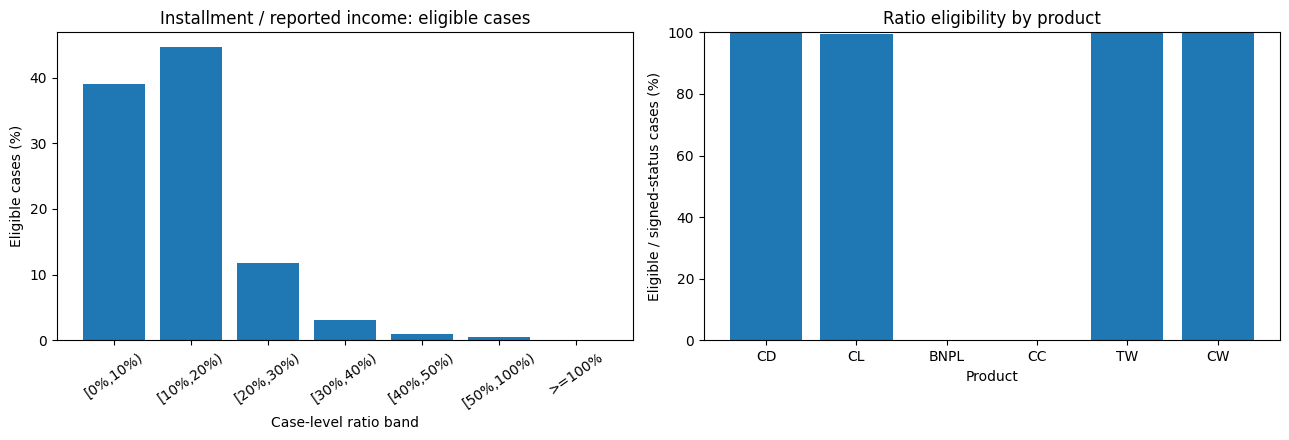

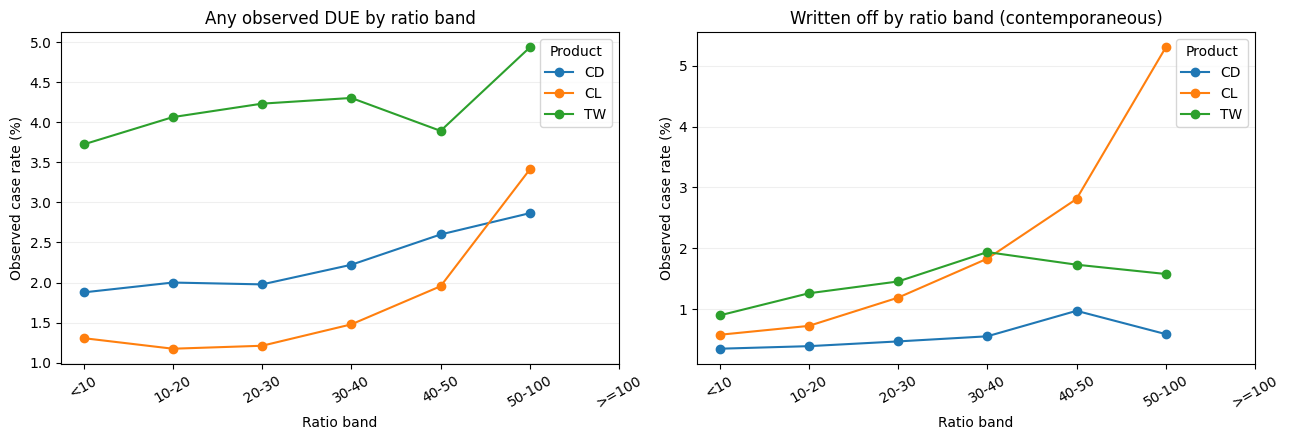

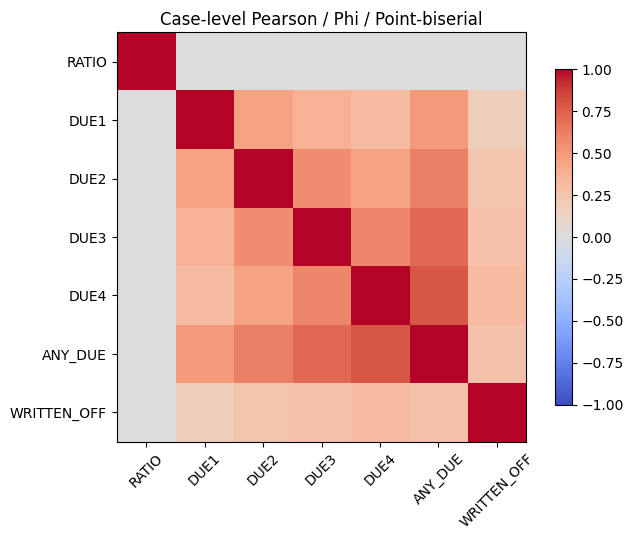

In [16]:
fig, axes = plt.subplots(1,2,figsize=(13,4.5))
main = ratio_bands.query("product == 'ALL'").sort_values('band_order')
axes[0].bar(main['ratio_band'],main['n_cases']/main['n_cases'].sum()*100)
axes[0].set(title='Installment / reported income: eligible cases',xlabel='Case-level ratio band',ylabel='Eligible cases (%)')
axes[0].tick_params(axis='x',rotation=35)
plot_df = coverage.query("product in ['CD','CL','TW','CW','BNPL','CC']").copy()
axes[1].bar(plot_df['product'],plot_df['ratio_coverage_pct'])
axes[1].set(title='Ratio eligibility by product',xlabel='Product',ylabel='Eligible / signed-status cases (%)',ylim=(0,100))
fig.tight_layout()
fig.savefig(FIG_DIR/'01_ratio_distribution_coverage.png',dpi=160,bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1,2,figsize=(13,4.5))
for prod in ['CD','CL','TW']:
    v = ratio_bands.loc[(ratio_bands['product']==prod)&(ratio_bands['n_due_available']>=100)].sort_values('band_order')
    if not v.empty:
        axes[0].plot(v['band_order'],v['any_due_pct'],marker='o',label=prod)
        axes[1].plot(v['band_order'],v['written_off_pct'],marker='o',label=prod)
for ax,title in zip(axes,['Any observed DUE by ratio band','Written off by ratio band (contemporaneous)']):
    ax.set(title=title,xlabel='Ratio band',ylabel='Observed case rate (%)',xticks=range(1,8),xticklabels=['<10','10-20','20-30','30-40','40-50','50-100','>=100'])
    ax.tick_params(axis='x',rotation=30)
    ax.grid(axis='y',alpha=0.2)
    ax.legend(title='Product')
fig.tight_layout()
fig.savefig(FIG_DIR/'02_ratio_payment_by_product.png',dpi=160,bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7,5.5))
matrix = corr.to_numpy(dtype=float)
im = ax.imshow(matrix,cmap='coolwarm',vmin=-1,vmax=1)
ax.set(xticks=range(len(feature_names)),yticks=range(len(feature_names)),xticklabels=feature_names,yticklabels=feature_names,title='Case-level Pearson / Phi / Point-biserial')
ax.tick_params(axis='x',rotation=45)
fig.colorbar(im,ax=ax,shrink=0.82)
fig.tight_layout()
fig.savefig(FIG_DIR/'03_feature_associations.png',dpi=160,bbox_inches='tight')
plt.show()

In [17]:
def md_table(df, limit=30):
    part = df.head(limit).copy().replace([np.inf,-np.inf],np.nan).fillna('')
    header = '| ' + ' | '.join(str(c) for c in part.columns) + ' |'
    separator = '| ' + ' | '.join(['---']*len(part.columns)) + ' |'
    lines = ['| ' + ' | '.join(str(v).replace('|','/') for v in row) + ' |'
             for row in part.itertuples(index=False,name=None)]
    return '\n'.join([header,separator]+lines)

sections = [
    ('01 Data inventory','01_source_inventory',20),
    ('02 Case grain and quality','02_case_grain_quality',20),
    ('03 Data eligibility by product','03_product_eligibility',20),
    ('04 Exact ratio percentiles','04_ratio_exact_percentiles',20),
    ('04b Numeric distributions and correlations','04b_income_annuity_credit_by_product',20),
    ('05 Ratio bands and observed distress','05_ratio_bands_vs_distress',28),
    ('06 Selection bias: eligibility versus missing ratio','06_selection_bias_ratio_vs_no_ratio',22),
    ('07 Payment signals by product','07_due_by_product',20),
    ('08 DUE patterns','08_due_patterns_by_product',20),
    ('09 DUE versus Written off (cross-sectional association)','09_due_writtenoff_association',22),
    ('10 Feature association matrix','10_feature_correlation_phi_pointbiserial',20),
    ('11 Pairwise sample sizes','11_correlation_pairwise_n',20),
    ('12 Product and apply-year cohorts','12_vintage_product_bias',24),
    ('12b Ratio x product x vintage (first rows)','13b_ratio_by_product_and_cohort',25),
    ('13 Down payment exploratory','14_downpayment_exploratory_CD_TW',20),
    ('14 Customer-level evidence coverage','15_customer_component_coverage',20),
    ('15 Customer-level coverage groups','16_customer_coverage_segments',20)
]
report = ['# BI10 Challenge 1 - Statistical Evidence Report',
          '',f'- Clean data source: {CLEAN_DIR}',
          '- Granularity: unique SKP_CREDIT_CASE for associations; distinct SKP_CLIENT for customer coverage.',
          '- Income period is not confirmed: ratio is exploratory installment / reported income, NOT verified DTI.',
          '- DUE flags and Written off have no confirmed event timestamps: associations are NOT prospective prediction or causality.',
          '- Ratio eligibility requires positive consistent income and annuity in the same case, signed-status case.',
          '- Absent DUE flags or no DUE record is not proof of reliable repayment; observation maturity is unknown.',
          '- Resolved proxy uses Finished/Paid off/Written off; this does not validate a good/bad label.',
          '- p-values are not sufficient for feature selection; use effect sizes, cell counts, Wilson CI, products and cohorts.',
          '- Clean CSV files and any existing DuckDB database were not modified.', '']
for title,key,limit in sections:
    report.extend([f'## {title}','',md_table(RESULTS[key],limit),''])
report += ['## Required checks before scoring','',
           '1. Confirm AMT_INCOME_MAIN period and whether the cleaned zero/conflicts were imputed.',
           '2. Confirm whether Active means active at a common as-of date and whether all concurrent liabilities are observable.',
           '3. Confirm DUE1-DUE4 semantics and exposure/maturity denominator.',
           '4. Confirm Written off event date before using it as a future bad label.',
           '5. Validate feature conclusions after controlling for product, apply-year cohort and selection bias.',
           '6. If Written off is part of a payment score, it cannot independently validate the same score.',
           '']
report_file = RUN_DIR / 'C1_STATISTICAL_EVIDENCE_FOR_AI.md'
report_file.write_text('\n'.join(report),encoding='utf-8')
print('REPORT:',report_file)
print('TABLES:',TABLE_DIR)
print('FIGURES:',FIG_DIR)

TypeError: Invalid value '' for dtype 'Int64'